# Nivell 1 - Visualització analítica guiada en Python

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import plotly.express as px

def leer_fichero(ruta="N1-Ex.8__transactions.csv", sep=';', encoding='latin1'):
  df = pd.read_csv(ruta, sep=sep, encoding=encoding)
  return df

In [2]:
df = leer_fichero('/content/drive/MyDrive/Colab Notebooks/N1-Ex.8__transactions.csv', sep=';')
df.head()

,id,card_id,business_id,timestamp,amount,declined,product_ids,user_id,lat,longitude,discount_amount,tax_amount,shipping_amount,channel,campaign_id,device_type,is_international,decline_reason,distance_km
0,CDDA7E40-544D-47BB-A4ED-671DD8A950D9,CcS-6894,b-2466,2018-12-12 08:05:17,176.45,0,"75, 73, 98",2313,59.620510,16.559977,20.72,35.29,0.00,store,CHRISTMAS_PEAK,pos,0,NaN,129.25
1,09456357-8E9B-475A-8257-87A023699964,CcS-5135,b-2342,2024-05-20 22:49:08,206.65,0,3,554,45.764588,4.843057,3.08,33.61,4.99,online,NO_CAMPAIGN,mobile,0,NaN,0.57
2,C47C7C84-C174-4973-A76B-825A9DB5582A,CcS-8415,b-2250,2018-11-04 23:16:18,548.77,0,"92, 85, 36, 23",3834,39.224213,-0.288066,43.76,95.24,0.00,marketplace,CATEGORY_PUSH,desktop,1,NaN,1498.24
3,2FB526AA-3844-4DDF-AC09-2EBCC255EE76,CcS-6553,b-2610,2022-06-17 09:17:25,411.55,0,"5, 27",1972,39.475985,-0.376419,4.03,71.43,0.00,store,NO_CAMPAIGN,pos,0,NaN,0.68
4,0D877407-B85E-40D2-9229-6BD6F2B8DF0A,CcS-7678,b-2454,2020-11-29 07:29:16,410.65,0,"38, 32, 82, 62",3097,51.436570,5.478526,95.72,71.27,0.00,marketplace,BLACK_FRIDAY,mobile,0,NaN,78.46


# Exercici 1: Preguntes analítiques directes (sense integracions complexes)

Preguntes analítiques: (només utilitzant la taula de transaccions)

# 1. Com evoluciona el nombre de transaccions al llarg del temps?



> Selecciona la columna temporal adequada.
> Defineix el nivell temporal d'anàlisi.


Escogemos la columna timestamp y revisamos el rango de fechas para establecer el nivel temporal de analisis.

In [3]:
df["timestamp"].agg(["min", "max"])

,timestamp
min,2015-01-01 00:40:23
max,2024-12-31 23:31:55


Como va de 2015 a 2024, estableceremos el nivel temporal por año, que nos dará 10 periodos de analisis. Por ahora, la columna timestamp es de tipo object.

In [4]:
df.dtypes

,0
id,object
card_id,object
business_id,object
timestamp,object
amount,float64
declined,int64
product_ids,object
user_id,int64
lat,float64
longitude,float64


Convertimos la columna 'timestamp' al formato nativo datetime64.

In [5]:
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/N1-Ex.8__transactions.csv', sep=';', parse_dates=["timestamp"])
df.head()

,id,card_id,business_id,timestamp,amount,declined,product_ids,user_id,lat,longitude,discount_amount,tax_amount,shipping_amount,channel,campaign_id,device_type,is_international,decline_reason,distance_km
0,CDDA7E40-544D-47BB-A4ED-671DD8A950D9,CcS-6894,b-2466,2018-12-12 08:05:17,176.45,0,"75, 73, 98",2313,59.620510,16.559977,20.72,35.29,0.00,store,CHRISTMAS_PEAK,pos,0,NaN,129.25
1,09456357-8E9B-475A-8257-87A023699964,CcS-5135,b-2342,2024-05-20 22:49:08,206.65,0,3,554,45.764588,4.843057,3.08,33.61,4.99,online,NO_CAMPAIGN,mobile,0,NaN,0.57
2,C47C7C84-C174-4973-A76B-825A9DB5582A,CcS-8415,b-2250,2018-11-04 23:16:18,548.77,0,"92, 85, 36, 23",3834,39.224213,-0.288066,43.76,95.24,0.00,marketplace,CATEGORY_PUSH,desktop,1,NaN,1498.24
3,2FB526AA-3844-4DDF-AC09-2EBCC255EE76,CcS-6553,b-2610,2022-06-17 09:17:25,411.55,0,"5, 27",1972,39.475985,-0.376419,4.03,71.43,0.00,store,NO_CAMPAIGN,pos,0,NaN,0.68
4,0D877407-B85E-40D2-9229-6BD6F2B8DF0A,CcS-7678,b-2454,2020-11-29 07:29:16,410.65,0,"38, 32, 82, 62",3097,51.436570,5.478526,95.72,71.27,0.00,marketplace,BLACK_FRIDAY,mobile,0,NaN,78.46


In [6]:
# Comprobamos que el tipo ya indica datetime64[ns]
df.dtypes

,0
id,object
card_id,object
business_id,object
timestamp,datetime64[ns]
amount,float64
declined,int64
product_ids,object
user_id,int64
lat,float64
longitude,float64


In [7]:
# Vemos tambien que al selectionar una celda de esta columna, nos devuelve un Timestamp.
df["timestamp"].iloc[0]

Timestamp('2018-12-12 08:05:17')

In [8]:
# Creamos la nueva columna "year" usando dt.year que extrae unicamente el año desde la columna timestamp
df.insert(3, 'year', df['timestamp'].dt.year)
df.head()


,id,card_id,business_id,year,timestamp,amount,declined,product_ids,user_id,lat,longitude,discount_amount,tax_amount,shipping_amount,channel,campaign_id,device_type,is_international,decline_reason,distance_km
0,CDDA7E40-544D-47BB-A4ED-671DD8A950D9,CcS-6894,b-2466,2018,2018-12-12 08:05:17,176.45,0,"75, 73, 98",2313,59.620510,16.559977,20.72,35.29,0.00,store,CHRISTMAS_PEAK,pos,0,NaN,129.25
1,09456357-8E9B-475A-8257-87A023699964,CcS-5135,b-2342,2024,2024-05-20 22:49:08,206.65,0,3,554,45.764588,4.843057,3.08,33.61,4.99,online,NO_CAMPAIGN,mobile,0,NaN,0.57
2,C47C7C84-C174-4973-A76B-825A9DB5582A,CcS-8415,b-2250,2018,2018-11-04 23:16:18,548.77,0,"92, 85, 36, 23",3834,39.224213,-0.288066,43.76,95.24,0.00,marketplace,CATEGORY_PUSH,desktop,1,NaN,1498.24
3,2FB526AA-3844-4DDF-AC09-2EBCC255EE76,CcS-6553,b-2610,2022,2022-06-17 09:17:25,411.55,0,"5, 27",1972,39.475985,-0.376419,4.03,71.43,0.00,store,NO_CAMPAIGN,pos,0,NaN,0.68
4,0D877407-B85E-40D2-9229-6BD6F2B8DF0A,CcS-7678,b-2454,2020,2020-11-29 07:29:16,410.65,0,"38, 32, 82, 62",3097,51.436570,5.478526,95.72,71.27,0.00,marketplace,BLACK_FRIDAY,mobile,0,NaN,78.46


> Compta el nombre de registres per període temporal.

> Ordena els resultats cronològicament.

In [9]:
# Con groupby, Pandas ya ordena los grupos de menor a mayor con el parametro sort activado por defecto, pero es más eficiente ordenar solo el resultado final con .sort_index()
registros_anuales = df.groupby('year', sort=False)['id'].count().sort_index()
registros_anuales

,id
year,
2015,9870
2016,9855
2017,9915
2018,9912
2019,10015
2020,10093
2021,10298
2022,10106
2023,9985


> Visualitza l'evolució amb un gràfic de línies amb pandas



> Visualització senzilla en Python sense utilitzar IA


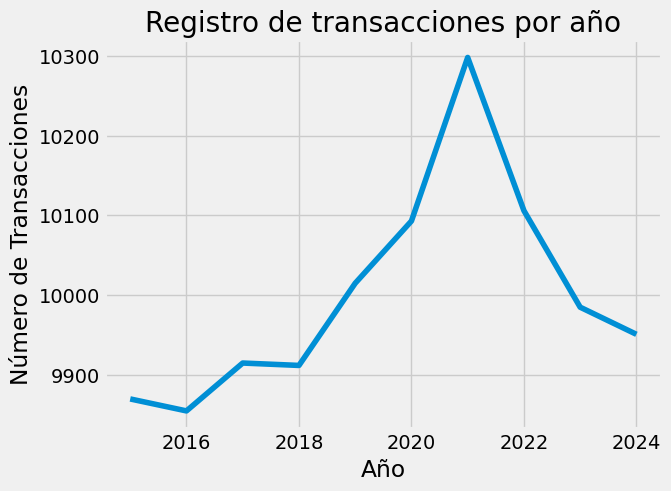

In [10]:
plt.style.use('fivethirtyeight') # nombre del estilo/plantilla (desde plt.style.available) para visualizar el grafico
registros_anuales.plot(kind="line", title='Registro de transacciones por año', # titulo del grafico
    ylabel='Número de Transacciones', # etiqueta eje y
    xlabel='Año',                  # etiqueta eje x
)

plt.show()



> Interpreta breument el resultat obtingut.


Al tener 10 periodos de analisis, el grafico se lee muy bien, observamos:

- un aumento sostenido del numero de transacciones de 2014 hasta alcanzar su mayor registro en 2021.

- una aceleración muy marcada entre 2020 y 2021.

- tras el pico de 2021, un descenso constante del numero de transacciones.
     

> Utilitza les eines d'IA disponibles a Colab per proposar una visualització alternativa.

**Prompt Gemini:**

proponme otra alternativa de visualizacion con pandas que permite analizar el numero de transacciones a lo largo del tiempo

**Respuesta Gemini:**

Alternativa de Visualización: Gráfico de Barras con pandas y color personalizado

Podemos utilizar un gráfico de barras (`kind='bar'`) directamente desde el método `.plot()` de pandas. Esto nos permite comparar de forma más directa y estructurada los volúmenes de transacciones entre los diferentes años.

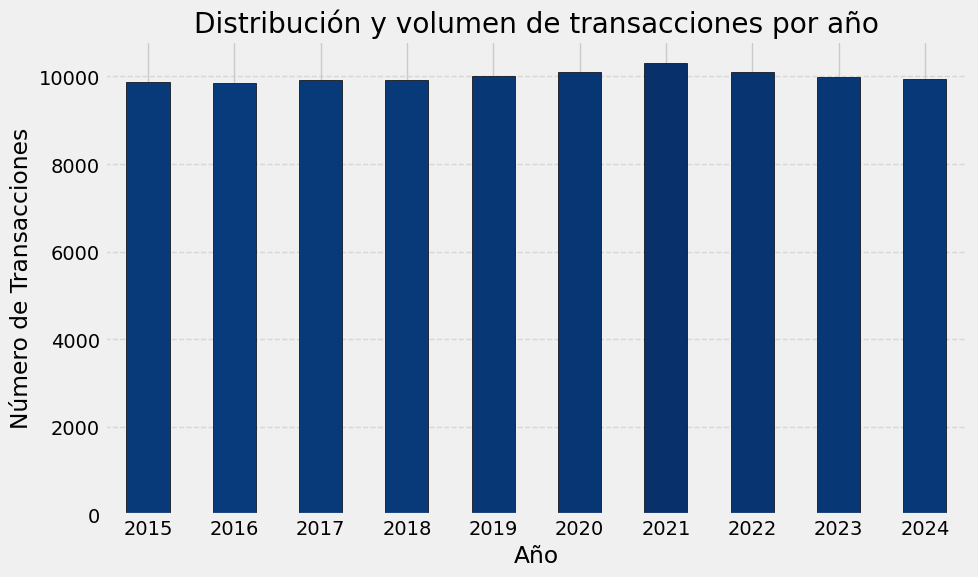

In [11]:
# Definimos una paleta de colores basada en la intensidad de las transacciones
colors = plt.cm.Blues(registros_anuales / registros_anuales.max())

# Creamos el gráfico de barras directamente con pandas
registros_anuales.plot(
    kind='bar',
    color=colors,
    edgecolor='black',
    figsize=(10, 6),
    title='Distribución y volumen de transacciones por año',
    xlabel='Año',
    ylabel='Número de Transacciones'
)

# Rotamos las etiquetas del eje X para que se lean perfectamente
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

> Compara el resultat inicial amb el resultat proposat per la IA i valora críticament si la nova proposta és una millora o un empitjorament, justificant la teva decisió.


El grafico propuesto por Gemini se ve peor porque el axis vertical del numero de transacciones empieza en 0, con lo cual la diferencia entre cada año casi no se aprecia.

**Apunte sobre la diferencia entre graficos:**

Gráfico de Líneas (mi código): Los gráficos de líneas están diseñados para mostrar la tendencia y los cambios entre puntos. Por esta razón, matplotlib autoajusta los límites del eje Y al rango de datos para que la pendiente y la tendencia se aprecien claramente. No tiene la obligación matemática de empezar en 0.

Gráfico de Barras (código Gemini): En un gráfico de barras, la altura de la barra representa visualmente la cantidad total. Si el eje Y no empezara en 0, las proporciones visuales se romperían por completo. Por este motivo de diseño estadístico, matplotlib fuerza estrictamente a que el eje Y comience en 0 de manera predeterminada al usar kind='bar'.

# 2. Quins usuaris generen més volum de facturació?



> Identifica la columna que representa el usuari.

La columna que representa el usuario es user_id



> Agrupa les transaccions per usuari i calcula el volum total de facturació sumant la columna amount.

In [12]:
facturacion_usuarios= df.groupby('user_id').agg(numero_de_transacciones=("user_id", "count"),volumen_facturacion=("amount", "sum"))
facturacion_usuarios

,numero_de_transacciones,volumen_facturacion
user_id,,
1,26,8146.82
2,30,8499.33
3,32,9338.36
4,29,8023.33
5,38,11364.69
...,...,...
4996,23,5712.60
4997,16,5930.18
4998,22,6696.73


> Ordena els usuaris de major a menor volum de facturació.

In [13]:
facturacion_usuarios = facturacion_usuarios.sort_values(by='volumen_facturacion', ascending=False)
facturacion_usuarios.head()

,numero_de_transacciones,volumen_facturacion
user_id,,
289,94,47332.90
318,91,47133.55
455,66,41396.68
417,78,37393.91
185,110,34576.49



> Selecciona els N usuaris principals (per exemple, els 15 primers).

In [14]:
top_15= facturacion_usuarios.nlargest(15, 'volumen_facturacion')
top_15

,numero_de_transacciones,volumen_facturacion
user_id,,
289,94,47332.90
318,91,47133.55
455,66,41396.68
417,78,37393.91
185,110,34576.49
285,70,33383.56
454,81,29528.42
349,53,27835.38
193,67,27462.59



> Representa el resultat mitjançant un gràfic de barres utilitzant Seaborn

> Construeix una visualització senzilla en Python sense utilitzar IA.

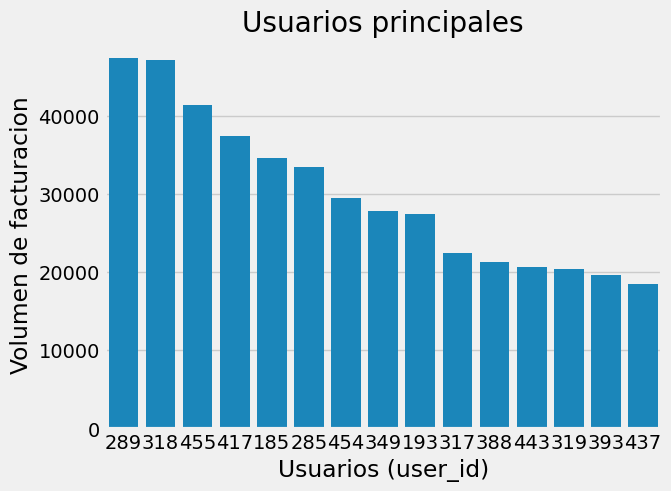

In [15]:
#  nota: Seaborn asume por defecto que el eje es cuantitativo. En lugar de tratar los IDs como "etiquetas de texto" los interpreta como posiciones.
sns.barplot(
    data=top_15.reset_index(),
    x="user_id",
    y="volumen_facturacion",
    order=top_15.reset_index().sort_values('volumen_facturacion', ascending=False)['user_id'] # Usamos reset_index() temporalmente para que 'user_id' pase de ser el índice a ser una columna normal, y asi poder ordenar de mayor a menor
)

plt.title("Usuarios principales")
plt.xlabel("Usuarios (user_id)")
plt.ylabel("Volumen de facturacion")

plt.show()

> Interpreta breument el resultat obtingut.

Agrandar el grafico permitiria una lectura de los user_id menos confusa.

Aun asi, podemos distinguir muy bien la diferencia de facturacion dentro del top 15 de usuarios.

Los usuarios 289 y 318 destacan por estar por encima de los 40.000€ mientras 393 y 437, estan por debajo de los 20.000€.

O sea que dentro de los 15 usuarios que más facturan, los 2 primeros facturan el doble que los 2 últimos.

El top 6 está por encima de los 30.000€, y la mayoria se mueve entre los 35.000€ y 20.000€ de facturacion.

> Utilitza les eines d'IA disponibles a Colab per proposar una visualització alternativa.

**Prompt Gemini:**

proponme otra alternativa de visualizacion con pandas que permita analizar que usuarios generan más volumen de facturación.

**Respuesta Gemini:**

Alternativa de Visualización: Gráfico de Barras Horizontal Combinado

Un gráfico de barras horizontal (`kind='barh'`) es ideal cuando tenemos etiquetas categóricas (como los `user_id`), ya que permite leer los valores del eje vertical cómodamente sin tener que rotar el texto. Además, podemos pintar las barras en función de una secuencia de color para destacar visualmente el podio.

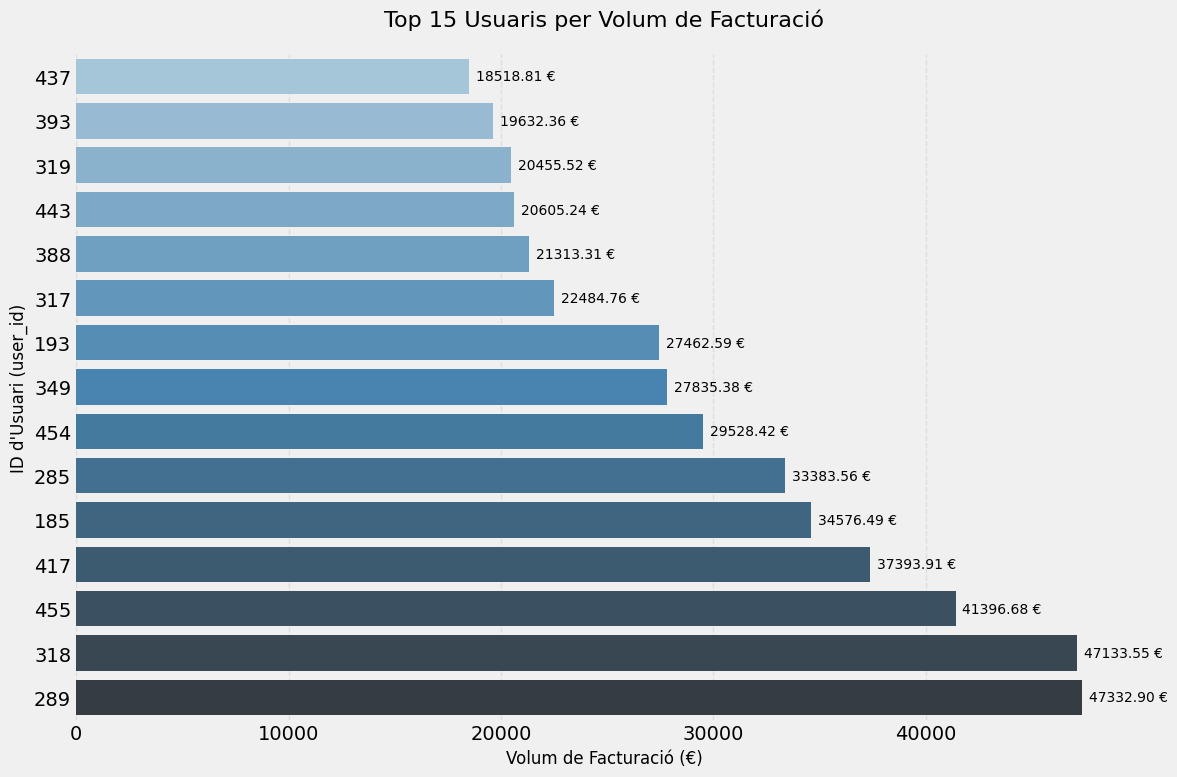

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# Preparem les dades ordenades de menor a major perquè en el gràfic horitzontal es llegeixi de dalt a baix
top_15_sorted = top_15.sort_values(by='volumen_facturacion', ascending=True).reset_index()
top_15_sorted['user_id'] = top_15_sorted['user_id'].astype(str) # Convertim a text per evitar que seaborn ho tracti com a numèric continu

# Configurem la figura
plt.figure(figsize=(12, 8))

# Utilitzem un degradat de colors per donar més pes visual als que facturen més
palette = sns.color_palette("Blues_d", n_colors=len(top_15_sorted))

ax = sns.barplot(
    data=top_15_sorted,
    x="volumen_facturacion",
    y="user_id",
    palette=palette,
    hue="user_id",
    legend=False
)

# Afegim els valors absoluts al final de cada barra per facilitar la lectura exacta
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f €', padding=5, fontsize=10)

plt.title("Top 15 Usuaris per Volum de Facturació", fontsize=16, pad=20)
plt.xlabel("Volum de Facturació (€)", fontsize=12)
plt.ylabel("ID d'Usuari (user_id)", fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.5)

sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

> Compara el resultat inicial amb el resultat proposat per la IA i valora críticament si la nova proposta és una millora o un empitjorament, justificant la teva decisió.

Las etiquetas de los user_id se ven mucho mejor y que aparezca la cantidad de facturacion de cada usuario facilita la comprehension.

El degradado de color guía el ojo y hace la lectura muy intuitiva. Tambien destaca este grafico por tener un diseño más elegante.



# 3. Hi ha diferències en la distribució de l'import de les transaccions segons l'hora del dia i si han estat acceptades o rebutjades?

> Crea una nova columna amb l'hora del dia a partir del timestamp.

In [17]:
# Creamos la nueva columna "time" usando dt.time
df.insert(5, 'time', df['timestamp'].dt.time)
df.head()

,id,card_id,business_id,year,timestamp,time,amount,declined,product_ids,user_id,...,longitude,discount_amount,tax_amount,shipping_amount,channel,campaign_id,device_type,is_international,decline_reason,distance_km
0,CDDA7E40-544D-47BB-A4ED-671DD8A950D9,CcS-6894,b-2466,2018,2018-12-12 08:05:17,08:05:17,176.45,0,"75, 73, 98",2313,...,16.559977,20.72,35.29,0.00,store,CHRISTMAS_PEAK,pos,0,NaN,129.25
1,09456357-8E9B-475A-8257-87A023699964,CcS-5135,b-2342,2024,2024-05-20 22:49:08,22:49:08,206.65,0,3,554,...,4.843057,3.08,33.61,4.99,online,NO_CAMPAIGN,mobile,0,NaN,0.57
2,C47C7C84-C174-4973-A76B-825A9DB5582A,CcS-8415,b-2250,2018,2018-11-04 23:16:18,23:16:18,548.77,0,"92, 85, 36, 23",3834,...,-0.288066,43.76,95.24,0.00,marketplace,CATEGORY_PUSH,desktop,1,NaN,1498.24
3,2FB526AA-3844-4DDF-AC09-2EBCC255EE76,CcS-6553,b-2610,2022,2022-06-17 09:17:25,09:17:25,411.55,0,"5, 27",1972,...,-0.376419,4.03,71.43,0.00,store,NO_CAMPAIGN,pos,0,NaN,0.68
4,0D877407-B85E-40D2-9229-6BD6F2B8DF0A,CcS-7678,b-2454,2020,2020-11-29 07:29:16,07:29:16,410.65,0,"38, 32, 82, 62",3097,...,5.478526,95.72,71.27,0.00,marketplace,BLACK_FRIDAY,mobile,0,NaN,78.46


In [18]:
# Creamos una columna "hour" solo con la hora, sin minutos ni segundas
df.insert(6, 'hour', df['timestamp'].dt.hour)
df.head()

,id,card_id,business_id,year,timestamp,time,hour,amount,declined,product_ids,...,longitude,discount_amount,tax_amount,shipping_amount,channel,campaign_id,device_type,is_international,decline_reason,distance_km
0,CDDA7E40-544D-47BB-A4ED-671DD8A950D9,CcS-6894,b-2466,2018,2018-12-12 08:05:17,08:05:17,8,176.45,0,"75, 73, 98",...,16.559977,20.72,35.29,0.00,store,CHRISTMAS_PEAK,pos,0,NaN,129.25
1,09456357-8E9B-475A-8257-87A023699964,CcS-5135,b-2342,2024,2024-05-20 22:49:08,22:49:08,22,206.65,0,3,...,4.843057,3.08,33.61,4.99,online,NO_CAMPAIGN,mobile,0,NaN,0.57
2,C47C7C84-C174-4973-A76B-825A9DB5582A,CcS-8415,b-2250,2018,2018-11-04 23:16:18,23:16:18,23,548.77,0,"92, 85, 36, 23",...,-0.288066,43.76,95.24,0.00,marketplace,CATEGORY_PUSH,desktop,1,NaN,1498.24
3,2FB526AA-3844-4DDF-AC09-2EBCC255EE76,CcS-6553,b-2610,2022,2022-06-17 09:17:25,09:17:25,9,411.55,0,"5, 27",...,-0.376419,4.03,71.43,0.00,store,NO_CAMPAIGN,pos,0,NaN,0.68
4,0D877407-B85E-40D2-9229-6BD6F2B8DF0A,CcS-7678,b-2454,2020,2020-11-29 07:29:16,07:29:16,7,410.65,0,"38, 32, 82, 62",...,5.478526,95.72,71.27,0.00,marketplace,BLACK_FRIDAY,mobile,0,NaN,78.46


> Construeix una visualització senzilla en Python sense utilitzar IA.

> Utilitza un violinplot de seaborn per analitzar la distribució dels imports.


> Assigna: x per l'hora del dia, y per l'import de la transacció i hue per l'estat de la transacció.

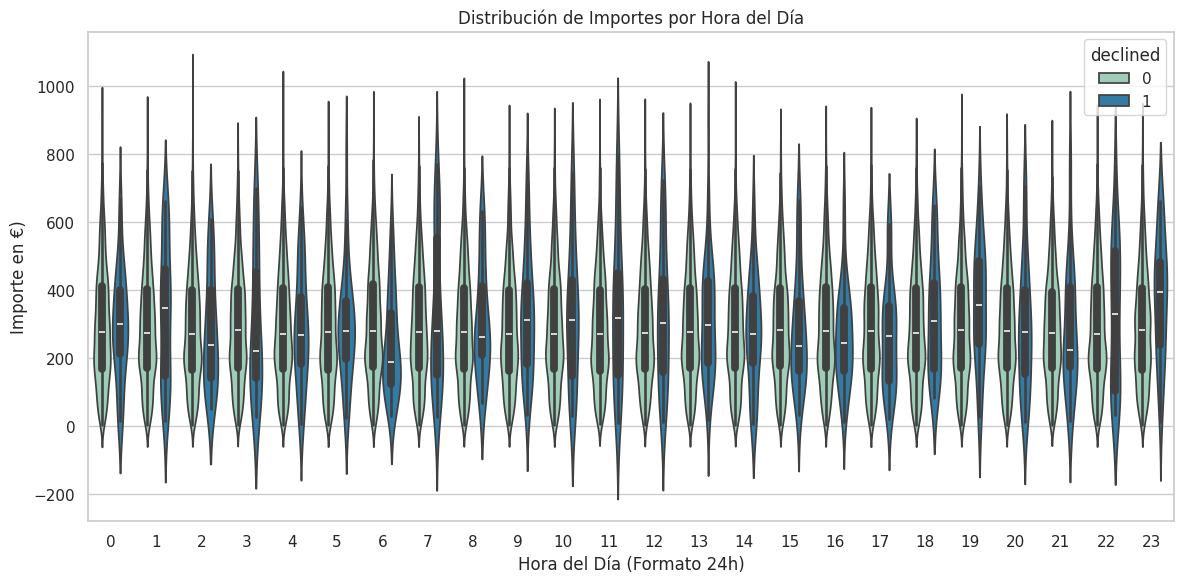

In [19]:
# estilo visual
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))

# creacion del grafico
sns.violinplot(
    data=df,
    x='hour',  # asignamos la hora en X
    y='amount', # asignamos el importe en Y
    palette='YlGnBu',
    hue='declined',  # agrupa las transacciones por estado, se muestra un violin para "aceptadas" y otro para "denegadas"
)
# Personalizamos titulo y nombre de los axis
plt.title('Distribución de Importes por Hora del Día')
plt.xlabel('Hora del Día (Formato 24h)')
plt.ylabel('Importe en €)')

plt.tight_layout()
plt.show()

> Activa split per comparar acceptades i rebutjades i inner amb quartile per mostrar mediana i quartils.

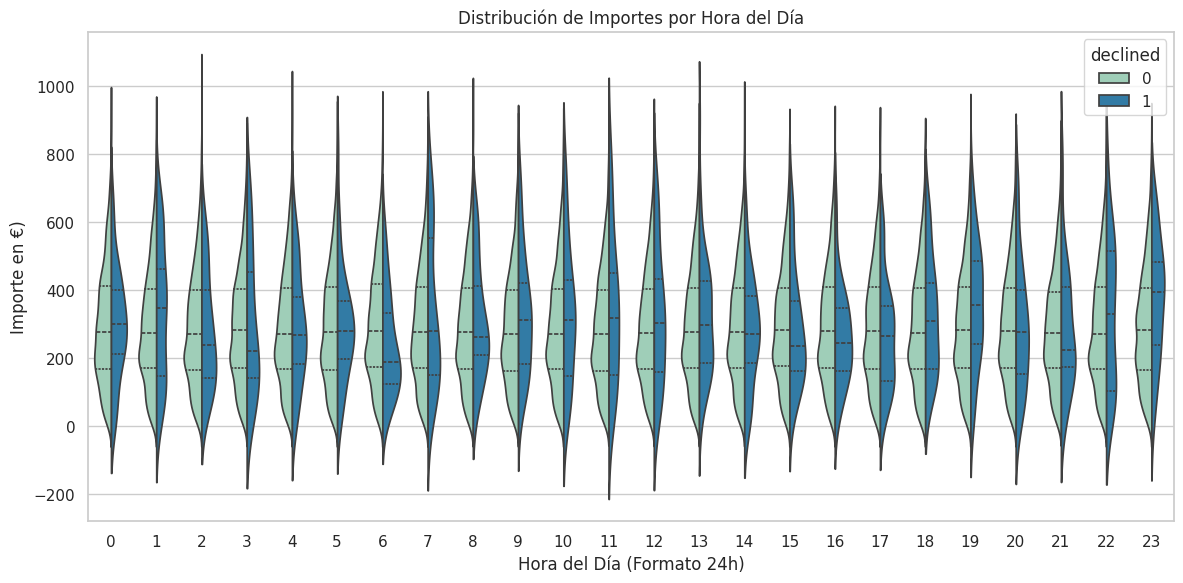

In [20]:
# estilo visual
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))

# creacion del grafico
sns.violinplot(
    data=df,
    x='hour',  # asignamos la hora en X
    y='amount', # asignamos el importe en Y
    palette='YlGnBu',
    hue='declined',  # agrupa las transacciones por estado
    split=True,      # divide el violin segun la columna establecida en hue
    inner='quartile' # representamos la mediana y cuartiles (se mostrarán con líneas discontinuas)
)
# Personalizamos titulo y nombre de los axis
plt.title('Distribución de Importes por Hora del Día')
plt.xlabel('Hora del Día (Formato 24h)')
plt.ylabel('Importe en €)')

plt.tight_layout()
plt.show()

> Interpreta breument el resultat obtingut.

El grafico de violin resulta muy confuso para manejar este tipo de datos, intentar hacer una comparativa entre las 24 horas es complicado ya que cuesta mucho distinguir en que puntos varia la anchura de cada violin.

Los violines son muy parecidos a lo largo de la franja horaria. No destaca ninguna hora en la cual los importes fluctuan mucho.

Respecto al estado de transaccion, observamos una simetria bastante regular.
Las medianas rondan en torno a los 300 € en ambos estados, esto indica que el importe no influye en si una transacción es aceptada o rechazada.



> Utilitza les eines d'IA disponibles a Colab per proposar una visualització alternativa.

**Prompt Gemini:**

proponme otra alternativa de visualizacion que permite analizar la distribucion de los importes de las transacciones segun la hora del dia y si las transacciones están aceptadas o denegadas

**Respuesta Gemini:**

Para analizar la distribución de importes por hora y estado de transacción, una gran alternativa al gráfico de violín es usar un gráfico de cajas (box plot) facetado o bien agrupado y optimizado. El gráfico de cajas es más limpio para identificar valores atípicos (outliers) y comparar las medianas directamente. Voy a añadir el prompt para Gemini y la implementación del gráfico alternativo.

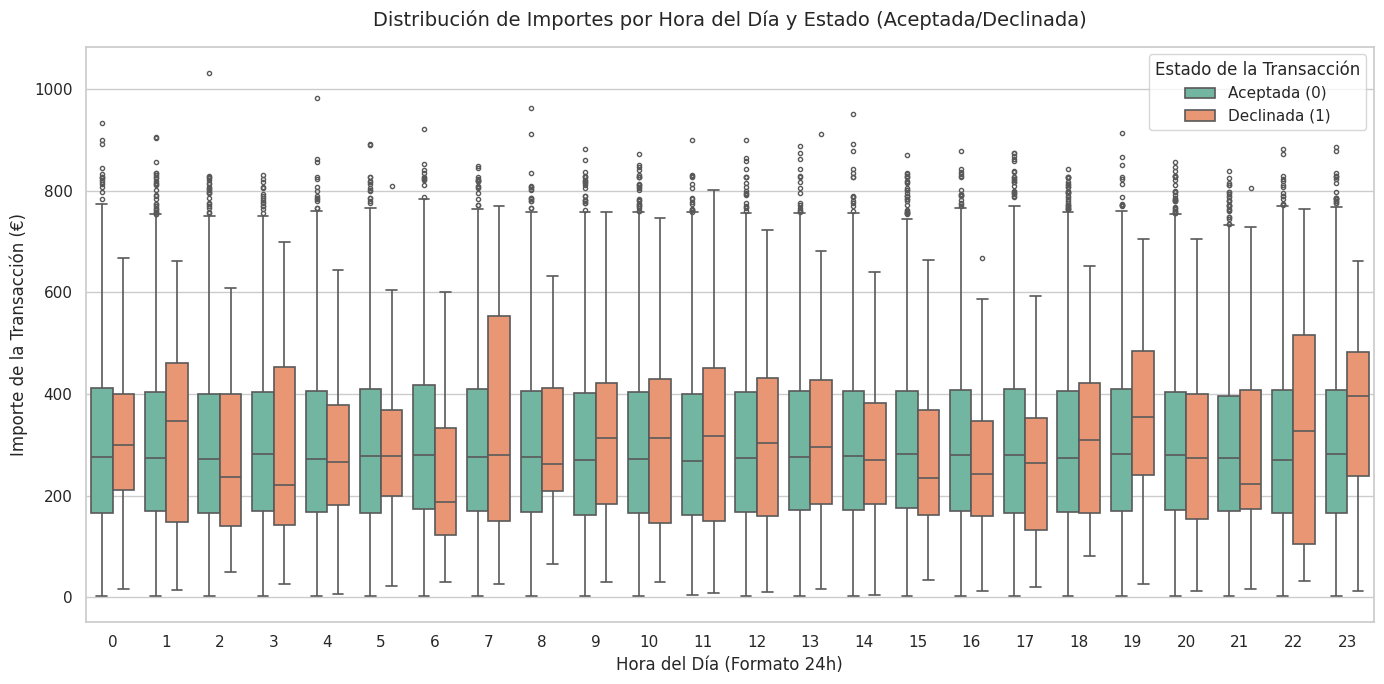

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 7))
sns.set_theme(style="whitegrid")

# Creamos el box plot agrupado por horas y distinguiendo el estado de la transacción
# Mapeamos la columna 'declined' para que la leyenda se genere de forma natural con los nombres correctos
df_temp = df.copy()
df_temp['Estado Transacción'] = df_temp['declined'].map({0: 'Aceptada (0)', 1: 'Declinada (1)'})

sns.boxplot(
    data=df_temp,
    x='hour',
    y='amount',
    hue='Estado Transacción',
    palette='Set2',
    fliersize=3, # Controlamos el tamaño de los puntos de outliers para no saturar la vista
    linewidth=1.2
)

plt.title('Distribución de Importes por Hora del Día y Estado (Aceptada/Declinada)', fontsize=14, pad=15)
plt.xlabel('Hora del Día (Formato 24h)', fontsize=12)
plt.ylabel('Importe de la Transacción (€)', fontsize=12)

# Al dejar que Seaborn maneje la leyenda con la columna mapeada, los colores quedan perfectamente sincronizados
plt.legend(title='Estado de la Transacción')

plt.tight_layout()
plt.show()

> Compara el resultat inicial amb el resultat proposat per la IA i valora críticament si la nova proposta és una millora o un empitjorament, justificant la teva decisió.

El grafico de cajas parece más adaptado.

Se identifica perfectamente la mediana.

Observamos importes outliers concentrados particularmente en la transacciones Aceptadas.

No se muestran importes por debajo de 0€ tal como se veia en el grafico de violin.

Aqui resaltan picos muy claros en las cajas de las transacciones rechazadas de las 07:00 y de las 22:00, se ven mucho más alargadas y se puede interpretar como que el importe de las transacciones rechazadas abarcan un rango de importes mucho más amplio en esas horas.


# 4. Quins dies de la setmana es concentra més activitat de venda?

In [22]:
# Creamos una nueva columna "day_name" usando dt.day_name (es un metodo: requiere "()") que devuelve el día de la semana acorde a la fecha
df.insert(5, 'day_name', df['timestamp'].dt.day_name())
df.head()

,id,card_id,business_id,year,timestamp,day_name,time,hour,amount,declined,...,longitude,discount_amount,tax_amount,shipping_amount,channel,campaign_id,device_type,is_international,decline_reason,distance_km
0,CDDA7E40-544D-47BB-A4ED-671DD8A950D9,CcS-6894,b-2466,2018,2018-12-12 08:05:17,Wednesday,08:05:17,8,176.45,0,...,16.559977,20.72,35.29,0.00,store,CHRISTMAS_PEAK,pos,0,NaN,129.25
1,09456357-8E9B-475A-8257-87A023699964,CcS-5135,b-2342,2024,2024-05-20 22:49:08,Monday,22:49:08,22,206.65,0,...,4.843057,3.08,33.61,4.99,online,NO_CAMPAIGN,mobile,0,NaN,0.57
2,C47C7C84-C174-4973-A76B-825A9DB5582A,CcS-8415,b-2250,2018,2018-11-04 23:16:18,Sunday,23:16:18,23,548.77,0,...,-0.288066,43.76,95.24,0.00,marketplace,CATEGORY_PUSH,desktop,1,NaN,1498.24
3,2FB526AA-3844-4DDF-AC09-2EBCC255EE76,CcS-6553,b-2610,2022,2022-06-17 09:17:25,Friday,09:17:25,9,411.55,0,...,-0.376419,4.03,71.43,0.00,store,NO_CAMPAIGN,pos,0,NaN,0.68
4,0D877407-B85E-40D2-9229-6BD6F2B8DF0A,CcS-7678,b-2454,2020,2020-11-29 07:29:16,Sunday,07:29:16,7,410.65,0,...,5.478526,95.72,71.27,0.00,marketplace,BLACK_FRIDAY,mobile,0,NaN,78.46


In [23]:
# Comprobandolo en un calendario, el 12/12/2028 cayo efectivamente un miercoles.
df.loc[0, ['day_name', 'timestamp']]

,0
day_name,Wednesday
timestamp,2018-12-12 08:05:17


In [24]:
# Convertimos la columna en categórica para que los días queden ordenados de lunes a domingo

# Definimos el orden
orden_dias = [ 'Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

# Creamos la categoria segun el orden establecido con ordeded a True
df['day_name'] = pd.Categorical(df['day_name'], categories=orden_dias, ordered=True)

In [25]:
# Contamos las transacciones agrupadas por dia
ventas_por_dia = df.groupby('day_name')['id'].count()
ventas_por_dia

/tmp/ipykernel_701/3215211170.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  ventas_por_dia = df.groupby('day_name')['id'].count()


,id
day_name,
Monday,14122
Tuesday,14176
Wednesday,14272
Thursday,14516
Friday,14272
Saturday,14353
Sunday,14289


> Construeix una visualització senzilla en Python sense utilitzar IA.

Usaremos un grafico de lineas ya que aprendimos en el ejercio 1 que en este tipo de gráfico , se autoajusta los límites del eje Y al rango de datos, y esto nos interesa visto la poca variarion que hay.

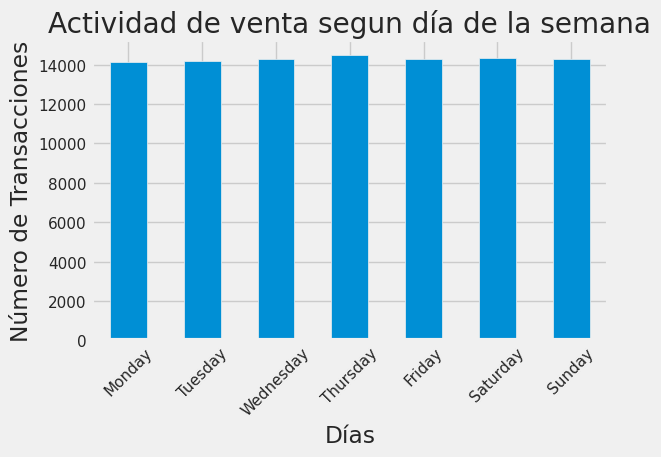

In [26]:
plt.style.use('fivethirtyeight')
ventas_por_dia.plot(
    kind='bar',
    title='Actividad de venta segun día de la semana',
    ylabel='Número de Transacciones',
    xlabel='Días'
)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

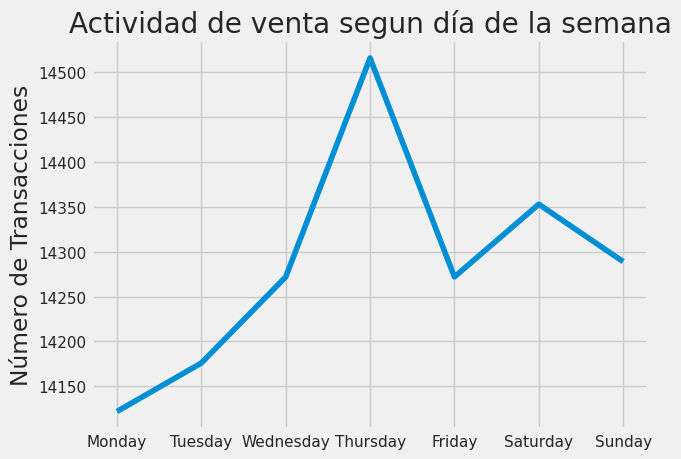

In [27]:
plt.style.use('fivethirtyeight') # nombre del estilo/plantilla (desde plt.style.available) para visualizar el grafico
ventas_por_dia.plot( title='Actividad de venta segun día de la semana', # titulo del grafico
    ylabel='Número de Transacciones', # etiqueta eje y
    xlabel='',                  # etiqueta eje x, lo dejamos en blanco, indicar "dias de la semana" no es necesario
)

plt.show()

> Interpreta breument el resultat obtingut.

El grafico se lee bastante bien.

Las ventas aumentan de lunes a jueves donde se alcanza el pico de ventas.

Las ventas del fin de semana son algo superior al principio de semana.

> Utilitza les eines d'IA disponibles a Colab per proposar una visualització alternativa.

**Prompt Gemini:**
proponme otra alternativa de visualizacion con pandas que permita analizar qué dias de la semana concentran más actividad de venta

**Respuesta Gemini:**

Una alternativa ideal al gráfico de barras tradicional para este tipo de datos es un gráfico de líneas con marcadores y etiquetas de datos (data labels).

Dado que la variación entre los días de la semana es numéricamente pequeña (oscila entre 14,122 y 14,516 transacciones), un gráfico de líneas permite ajustar el eje Y para hacer zoom en la diferencia real, mostrando de forma óptima la "curva de actividad" semanal sin distorsionar la interpretación.

> Compara el resultat inicial amb el resultat proposat per la IA i valora críticament si la nova proposta és una millora o un empitjorament, justificant la teva decisió.

El tipo de grafico propuesto por Gemini es el mismo que usamos, mejora sobre todo a nivel estetico y mostrando los valores absolutos que permite una interpretacion mas directa.

# Exercici 2: Preguntes analítiques complexes (amb guia)

Per a cada pregunta:

» Descriu breument els passos seguits.

» Mostra la visualització final.

» Interpreta què implica per al negoci.

# » Depenem excessivament d'un nombre reduït de països de companyies venedores?

1. Combinar la informació de transaccions amb la de companyies.

2. Agrupar la facturació per país.

3. Calcular la facturació total generada per cada país.

4. Ordenar els països de major a menor facturació.

5. Calcular el percentatge acumulat sobre el total.

6. Visualitzar.

In [28]:
# importamos el fichero de companies
df_companies = leer_fichero('/content/drive/MyDrive/Colab Notebooks/N1-Ex.8__companies.csv', sep=',')
df_companies.head()

,company_id,company_name,phone,email,country,website,merchant_category,merchant_price_position
0,b-2222,Ac Fermentum Incorporated,+64 601 244 6320,donec.porttitor.tellus@yahoo.net,Germany,https://www.ac-fermentum-incorporated.com,Beauty,mid-market
1,b-2226,Magna A Neque Industries,+33 823 560 3779,risus.donec.nibh@icloud.org,Australia,https://www.magna-a-neque-industries.com,Travel,budget
2,b-2230,Fusce Corp.,+29 657 646 4324,risus@protonmail.edu,United States,https://www.fusce-corp.com,Home,mid-market
3,b-2234,Convallis In Incorporated,+6 693 982 1255,mauris.ut@aol.couk,Germany,https://www.convallis-in-incorporated.com,Sports,mid-market
4,b-2238,Ante Iaculis Nec Foundation,+69 914 549 1009,sed.dictum.proin@outlook.ca,New Zealand,https://www.ante-iaculis-nec-foundation.com,Toys,mid-market


In [29]:
# combinamos transacciones con companies con merge
tx_co = pd.merge(
    df, # df izquierdo
    df_companies, # df derecho
    left_on=['business_id'], # nombre columnas en df de la izquierda
    right_on=['company_id'], # nombre columnas en df de la derecha
    how='left' # left join
)
tx_co.head()

,id,card_id,business_id,year,timestamp,day_name,time,hour,amount,declined,...,decline_reason,distance_km,company_id,company_name,phone,email,country,website,merchant_category,merchant_price_position
0,CDDA7E40-544D-47BB-A4ED-671DD8A950D9,CcS-6894,b-2466,2018,2018-12-12 08:05:17,Wednesday,08:05:17,8,176.45,0,...,NaN,129.25,b-2466,Amet Lorem LLP,+40 468 847 7738,ultricies.adipiscing@icloud.edu,Spain,https://www.amet-lorem-llp.com,Toys,mid-market
1,09456357-8E9B-475A-8257-87A023699964,CcS-5135,b-2342,2024,2024-05-20 22:49:08,Monday,22:49:08,22,206.65,0,...,NaN,0.57,b-2342,Fringilla Porttitor Incorporated,+81 232 896 8043,ultrices.a.auctor@protonmail.couk,Sweden,https://www.fringilla-porttitor-incorporated.com,Electronics,mid-market
2,C47C7C84-C174-4973-A76B-825A9DB5582A,CcS-8415,b-2250,2018,2018-11-04 23:16:18,Sunday,23:16:18,23,548.77,0,...,NaN,1498.24,b-2250,Amet Nulla Donec Corporation,+96 338 276 8449,mattis.integer.eu@protonmail.net,Italy,https://www.amet-nulla-donec-corporation.com,Gaming,budget
3,2FB526AA-3844-4DDF-AC09-2EBCC255EE76,CcS-6553,b-2610,2022,2022-06-17 09:17:25,Friday,09:17:25,9,411.55,0,...,NaN,0.68,b-2610,Egestas Nunc Sed Limited,+39 297 745 2202,vitae@hotmail.edu,Italy,https://www.egestas-nunc-sed-limited.com,Books,budget
4,0D877407-B85E-40D2-9229-6BD6F2B8DF0A,CcS-7678,b-2454,2020,2020-11-29 07:29:16,Sunday,07:29:16,7,410.65,0,...,NaN,78.46,b-2454,Justo Eu Arcu Ltd,+68 493 166 1232,ac.facilisis@icloud.couk,Italy,https://www.justo-eu-arcu-ltd.com,Travel,mid-market


In [30]:
# calculamos y ordenamos la suma de ventas agrupando por pais
# sort_values, ordena por columna amount, de mayor a menor
# reinicialimos country como columna con reset_index para que seaborn pueda usarla luego
ventas_por_pais = tx_co.groupby('country')[['amount']].sum().sort_values(by='amount', ascending=False).reset_index()
ventas_por_pais

,country,amount
0,Sweden,4928290.24
1,Netherlands,4506571.38
2,United Kingdom,4099117.08
3,Italy,4087557.38
4,Germany,4020364.07
5,France,1416084.26
6,United States,1101737.27
7,Belgium,952208.75
8,Norway,809288.82
9,Ireland,715220.46


In [31]:
# calculamos el porcentaje acumulado con cumsum

ventas_por_pais['porcentaje'] = ventas_por_pais['amount'] / ventas_por_pais['amount'].sum() * 100
ventas_por_pais['porcentaje_acumulado'] = ventas_por_pais['porcentaje'].cumsum()
ventas_por_pais


,country,amount,porcentaje,porcentaje_acumulado
0,Sweden,4928290.24,16.822702,16.822702
1,Netherlands,4506571.38,15.383166,32.205867
2,United Kingdom,4099117.08,13.992322,46.198189
3,Italy,4087557.38,13.952863,60.151052
4,Germany,4020364.07,13.723499,73.874551
5,France,1416084.26,4.833799,78.708350
6,United States,1101737.27,3.760776,82.469126
7,Belgium,952208.75,3.250361,85.719487
8,Norway,809288.82,2.762505,88.481992
9,Ireland,715220.46,2.441403,90.923394


Escogemos un grafico combinado de barras con linea (1 variable categorica en X y una variable numerica en Y)

Establecemos la altura de la linea al 80% siguiendo la regla del 80/20 del diagrama de Pareto que es un clásico para analizar ventas.

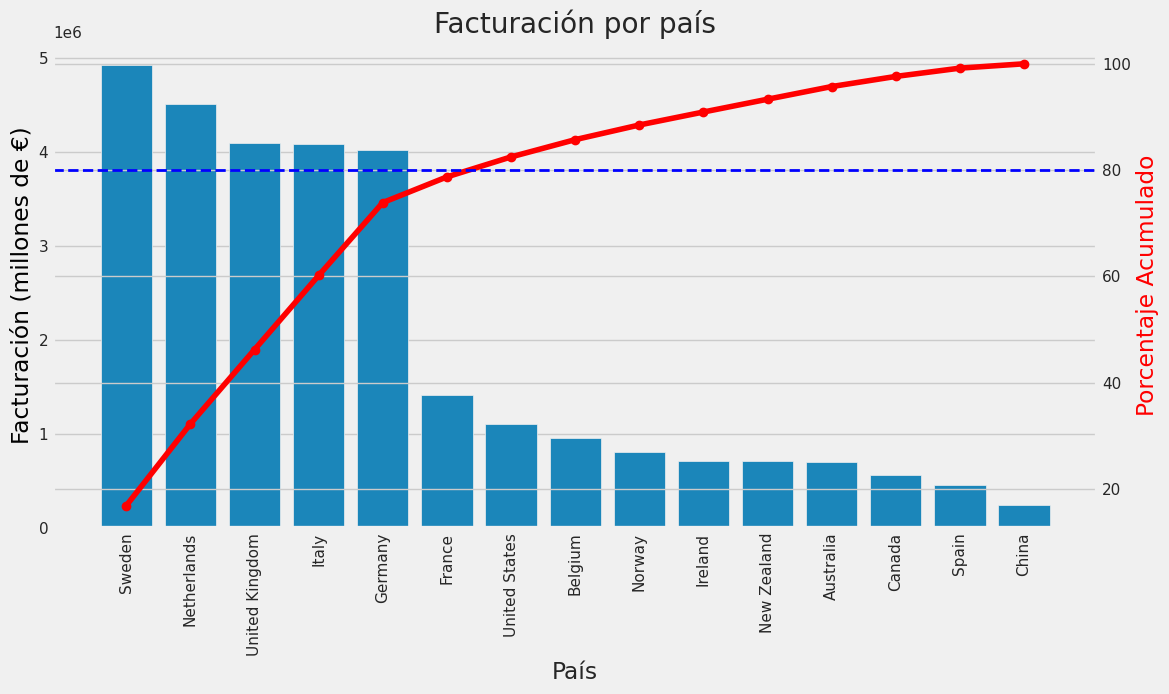

In [32]:
fig, ax1 = plt.subplots(figsize=(12, 6)) # se crea la figura y se configura el tamaño
plt.xticks(rotation=90) # gira las etiquetas de los paises para que que mejor lectura
plt.title('Facturación por país')

sns.barplot(data=ventas_por_pais, x='country', y='amount', ax=ax1)  # definimos el grafico de barras y sus axis
ax1.set_ylabel('Facturación (millones de €)', color='black')        # personalizamos las etiquetas de los axis, aqui Y: vertical
ax1.set_xlabel('País')                                              # aqui X: horizontal

# dibujamos la curva del porcentaje acumulado
ax2 = ax1.twinx()                                 # crea un segundo eje Y
ax2.plot(ventas_por_pais['country'],              # definimos X
         ventas_por_pais['porcentaje_acumulado'], # definimos Y
         color='red',                             # color='red' : linea roja
         marker='o',                              # marker='o' : añade un punto para cada país
         linestyle='-',                           # linestyle='-' : junta los puntos con una linea
         label='Porcentaje Acumulado')

ax2.set_ylabel('Porcentaje Acumulado', color='red')
ax2.axhline(        # creacion de la linea horizontal
    y=80,           # coloca la línea a la altura del valor 80 en el eje Y
    color='blue',   # linea de color azul
    linestyle='--', # linea discontinua
    linewidth=2)    # grosor de la linea


» Interpreta què implica per al negoci.

6 países (Suecia, Países Bajos, Reino Unido, Italia, Alemania y Francia) generan casi el 80% de la facturación total. Para llegar estrictamente a 80% deberiamos incluir un septimo país.

Dejando de lado el porcentaje acumulado, dependemos de 5 países (Suecia, Países Bajos, Reino Unido, Italia y Alemania). Destaca claramente en el grafico que facturan como minimo un 4M, mientras los 10 restantes facturan todos por debajo de 1.5M.

Podriamos decir que destaca un grupo de 5 paises como compradores vitales, pero que a ellos solos no suman el 80% de la facturacion, hemos de contar con un par de países más para llegar a 80%.

Dichos dos países, no tienen porque ser necesariamente Francia (sexto) Y Estados Unidos (septimo). Tambien llegariamos a 80% con Estados Unidos e Irlanda, o Francia y Belgica.



# » Existeix estacionalitat en les vendes?

1. Treballar amb dates de transacció.

2. Extreure la informació temporal rellevant (any i mes).

3. Calcular el volum total de vendes (suma de amount) per any i mes.

4. Comparar patrons temporals amb la comparació entre anys. Crea una taula tipus pivot.

5. Visualitzar l'evolució.

In [33]:
# Creamos la nueva columna "month" usando dt.month que extrae unicamente el mes desde la columna timestamp
df.insert(4, 'month', df['timestamp'].dt.month)
df.head()

,id,card_id,business_id,year,month,timestamp,day_name,time,hour,amount,...,longitude,discount_amount,tax_amount,shipping_amount,channel,campaign_id,device_type,is_international,decline_reason,distance_km
0,CDDA7E40-544D-47BB-A4ED-671DD8A950D9,CcS-6894,b-2466,2018,12,2018-12-12 08:05:17,Wednesday,08:05:17,8,176.45,...,16.559977,20.72,35.29,0.00,store,CHRISTMAS_PEAK,pos,0,NaN,129.25
1,09456357-8E9B-475A-8257-87A023699964,CcS-5135,b-2342,2024,5,2024-05-20 22:49:08,Monday,22:49:08,22,206.65,...,4.843057,3.08,33.61,4.99,online,NO_CAMPAIGN,mobile,0,NaN,0.57
2,C47C7C84-C174-4973-A76B-825A9DB5582A,CcS-8415,b-2250,2018,11,2018-11-04 23:16:18,Sunday,23:16:18,23,548.77,...,-0.288066,43.76,95.24,0.00,marketplace,CATEGORY_PUSH,desktop,1,NaN,1498.24
3,2FB526AA-3844-4DDF-AC09-2EBCC255EE76,CcS-6553,b-2610,2022,6,2022-06-17 09:17:25,Friday,09:17:25,9,411.55,...,-0.376419,4.03,71.43,0.00,store,NO_CAMPAIGN,pos,0,NaN,0.68
4,0D877407-B85E-40D2-9229-6BD6F2B8DF0A,CcS-7678,b-2454,2020,11,2020-11-29 07:29:16,Sunday,07:29:16,7,410.65,...,5.478526,95.72,71.27,0.00,marketplace,BLACK_FRIDAY,mobile,0,NaN,78.46


In [34]:
# Agrupamos ventas por año y por mes
ventas_por_periodo = df.groupby(['year', 'month'])['amount'].sum().reset_index()
ventas_por_periodo

,year,month,amount
0,2015,1,224946.23
1,2015,2,248775.83
2,2015,3,254702.98
3,2015,4,247957.49
4,2015,5,252596.43
...,...,...,...
115,2024,8,239210.63
116,2024,9,236592.54
117,2024,10,255720.13
118,2024,11,236354.15


In [35]:
# Creamos la tabla pivot
tabla_ventas = ventas_por_periodo.pivot(index='month', columns='year', values='amount')
tabla_ventas

year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
month,,,,,,,,,,
1,224946.23,227231.14,224391.23,229524.09,224592.71,234191.13,246993.53,226680.93,231075.91,227399.39
2,248775.83,251111.47,253354.90,246504.98,262006.66,249356.44,258837.10,237503.38,252680.15,253739.68
3,254702.98,248245.83,240338.05,239145.90,280530.50,260821.35,253110.77,274387.47,243909.57,248588.94
4,247957.49,242394.40,253125.97,237432.05,244347.66,246533.40,261597.02,241191.04,245386.83,245734.27
5,252596.43,243533.92,240919.28,246838.08,244739.50,254171.48,243414.73,279590.23,264790.26,257877.46
6,233084.63,233245.79,241065.64,243421.44,245470.13,238902.90,236504.81,261954.89,234527.22,247029.50
7,243774.43,238618.15,244380.32,233449.29,233962.91,242644.23,253553.62,235935.19,240041.34,231264.22
8,238550.36,238392.03,233894.55,231129.56,240040.21,234433.92,239433.71,246434.63,239288.98,239210.63
9,227985.24,242774.67,235830.55,238772.22,235021.45,258779.26,247648.05,255496.48,237105.34,236592.54


In [36]:
# Visualizacion de la tabla pivot
tabla_ventas_grafico = (
    tabla_ventas # de donde extraemos los datos
    .style # activamos la visualizacion
    .format("{:.2f}") # muestra 2 decimales
    .background_gradient(cmap='Blues') # crea el mapa de calor
)

display(tabla_ventas_grafico)

year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
month,,,,,,,,,,
1,224946.23,227231.14,224391.23,229524.09,224592.71,234191.13,246993.53,226680.93,231075.91,227399.39
2,248775.83,251111.47,253354.90,246504.98,262006.66,249356.44,258837.10,237503.38,252680.15,253739.68
3,254702.98,248245.83,240338.05,239145.90,280530.50,260821.35,253110.77,274387.47,243909.57,248588.94
4,247957.49,242394.40,253125.97,237432.05,244347.66,246533.40,261597.02,241191.04,245386.83,245734.27
5,252596.43,243533.92,240919.28,246838.08,244739.50,254171.48,243414.73,279590.23,264790.26,257877.46
6,233084.63,233245.79,241065.64,243421.44,245470.13,238902.90,236504.81,261954.89,234527.22,247029.50
7,243774.43,238618.15,244380.32,233449.29,233962.91,242644.23,253553.62,235935.19,240041.34,231264.22
8,238550.36,238392.03,233894.55,231129.56,240040.21,234433.92,239433.71,246434.63,239288.98,239210.63
9,227985.24,242774.67,235830.55,238772.22,235021.45,258779.26,247648.05,255496.48,237105.34,236592.54


» Interpreta què implica per al negoci.

Se observan patrones de estacionalidad:

- Los meses de febrero, marzo, mayo y octubre podrian formar la temporada alta, vemos una concentraciones de celdas oscuras en estos periodos.

- Sin embargo el mes de enero es, salvo 2020 y 2021 el mes con las ventas más bajas.

- La temporada de verano es muy estable. Los meses de junio, julio, agosto y septiembre son constante a lo largo de los diez años.

# » Anàlisi de concentració i variabilitat (tria UNA opció)
Opció A – Producte (Només si disposes de la taula de productes)

# Quins productes generen més ingressos i amb quina variabilitat?


1. Combinar transaccions, la taula pont i productes.

2. Calcular ingressos per producte amb un groupby, sum y sort.

3. Selecciona els top N productes: 15 per exemple.

4. Escollir una visualització adequada per analitzar dispersió.

In [37]:
# importamos el fichero de products
products = leer_fichero('/content/drive/MyDrive/Colab Notebooks/products.csv', sep=';')
transaction_products = leer_fichero('/content/drive/MyDrive/Colab Notebooks/transaction_products.csv', sep=';')

In [38]:
# Combinamos la tabla transactions con la tabla puente transaction_products
df_transaction_products = pd.merge(
    df,
    transaction_products,
    left_on=['id'],
    right_on=['transaction_id'],
    how='left',
    suffixes=('_transaction', '_transaction_product')
)
# Combinamos la tabla transaction_products con la tabla products
df2 = pd.merge(
    df_transaction_products,
    products,
    left_on=['product_id'],
    right_on=['id'],
    how='left',
    suffixes=('_transaction', '_product')
)
display(df2.head())

,id_transaction,card_id,business_id,year,month,timestamp,day_name,time,hour,amount,...,id,product_name,price,colour,weight,warehouse_id,category,brand,cost,launch_date
0,CDDA7E40-544D-47BB-A4ED-671DD8A950D9,CcS-6894,b-2466,2018,12,2018-12-12 08:05:17,Wednesday,08:05:17,8,176.45,...,75,giantsblood maester Karstark,9.46,#f9f9f9,1.5,WH-70,Food,FreshBox,6.46,2014-10-16
1,CDDA7E40-544D-47BB-A4ED-671DD8A950D9,CcS-6894,b-2466,2018,12,2018-12-12 08:05:17,Wednesday,08:05:17,8,176.45,...,73,Dorne bastard,114.09,#848484,1.0,WH-68,Electronics,PixelForge,80.50,2014-05-27
2,CDDA7E40-544D-47BB-A4ED-671DD8A950D9,CcS-6894,b-2466,2018,12,2018-12-12 08:05:17,Wednesday,08:05:17,8,176.45,...,98,Direwolf Littlefinger,38.33,#bababa,2.0,WH-93,Sports,Trail&Co,16.74,2014-07-26
3,09456357-8E9B-475A-8257-87A023699964,CcS-5135,b-2342,2024,5,2024-05-20 22:49:08,Monday,22:49:08,22,206.65,...,3,duel tourney Lannister,171.13,#d8d8d8,1.5,WH-2,Food,Daily Pantry,107.07,2013-08-18
4,C47C7C84-C174-4973-A76B-825A9DB5582A,CcS-8415,b-2250,2018,11,2018-11-04 23:16:18,Sunday,23:16:18,23,548.77,...,92,Stannis warden,168.49,#afafaf,1.4,WH-87,Food,Market&Co,105.96,2014-11-13


Aqui para calcular los ingressos hemos de escoger la columna price que responde a un producto. No podemos usar amount porque corresponde a la transaccion.

In [39]:
# Calculamos los ingresos por producto agrupando por el id del producto y su nombre, sumando y ordenando de mayor a menor
ingresos_por_producto = df2.groupby(['id', 'product_name']).agg(product_revenue = ('price', 'sum'), quantity = ('id', 'count'))
ingresos_por_producto = ingresos_por_producto.sort_values('product_revenue', ascending = False)

#Seleccionamos el top 10 de productos
top_10_productos = ingresos_por_producto.head(10).reset_index()
top_10_productos

,id,product_name,product_revenue,quantity
0,39,warden,505587.15,2571
1,64,Direwolf,502352.16,2568
2,67,Winterfell,500038.88,2552
3,15,Stannis warden,492525.15,2535
4,93,Littlefinger Tarly Stark,488241.00,2535
5,62,the duel,481608.06,2549
6,86,Stark kingsblood,478322.88,2528
7,63,Jade tatooine dooku,476353.08,2526
8,16,the duel warden,471813.28,2608
9,12,duel Direwolf,464532.80,2558


Ahora que tenemos los productos más vendidos, queremos saber como evolucionarion sus ventas a lo largo del tiempo.

In [40]:
# Extraemos los nombres de los 10 productos
lista_top_10 = top_10_productos['product_name'].tolist()

# Filtramos esos 10 productos el dataFrame original
df2_top_10 = df2[df2['product_name'].isin(lista_top_10)]

# Agrupamos por año y nombre de producto para calcular los ingresos anuales y las cantidades vendidas
ingresos_top10 = df2_top_10.groupby(['year', 'product_name']).agg(revenue_per_year = ('amount', 'sum'), quantity = ('id', 'count'))

ingresos_top10 = ingresos_top10.reset_index()
ingresos_top10

,year,product_name,revenue_per_year,quantity
0,2015,Direwolf,205456.12,474
1,2015,Jade tatooine dooku,105131.50,241
2,2015,Littlefinger Tarly Stark,102217.92,229
3,2015,Stannis warden,201750.40,475
4,2015,Stark kingsblood,105504.93,229
...,...,...,...,...
95,2024,Winterfell,340515.35,1016
96,2024,duel Direwolf,193640.96,515
97,2024,the duel,351462.99,991
98,2024,the duel warden,112314.60,251


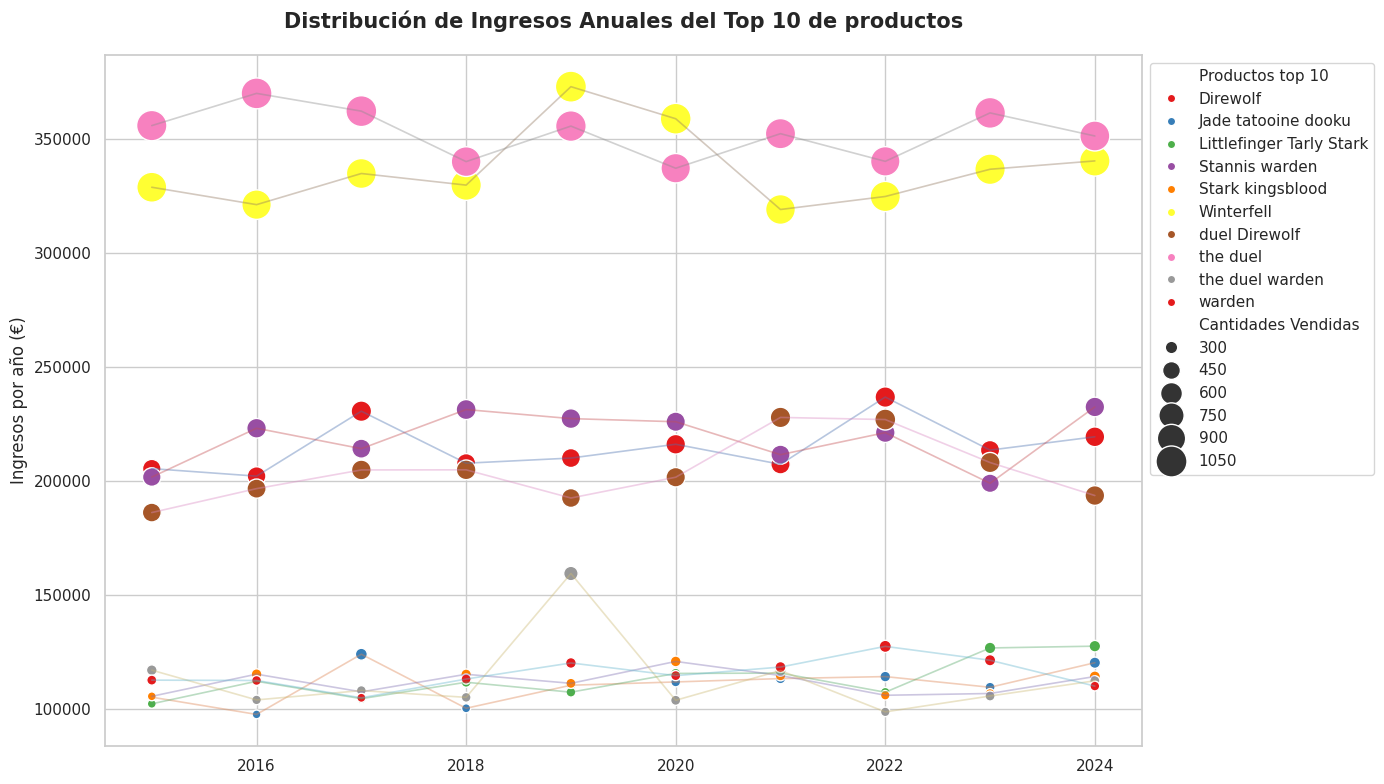

In [41]:
datos = ingresos_top10.rename(columns={'product_name': 'Productos top 10', 'quantity': 'Cantidades Vendidas'}) #renombramos las columnas tal como queremos que aparezcan en la leyenda / la variable es la que debemos poner en "data".

# Configuramos el estilo y tamaño
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(14, 8))

# Dibujamos los puntos (Scatter) y líneas combinadas con lineplot
sns.scatterplot(
    data=datos,
    x='year',              # definimos la columna del eje horizontal
    y='revenue_per_year',  # definimos la columna del eje vertical
    hue='Productos top 10',    # Diferencia los puntos por color según el producto
    palette='Set1',
    size='Cantidades Vendidas',       # el tamaño del punto es accorde a la cantidad
    sizes=(40, 500),       # tamaño de los puntos
    linewidth=1,
)
sns.lineplot(data=datos, x="year", y="revenue_per_year", hue="Productos top 10", alpha=0.4, linewidth=1.2, legend = False) # ajustamos la transparencia de linea con alpha

# Titulo y etiquetas de ejes
plt.title('Distribución de Ingresos Anuales del Top 10 de productos', fontsize=15, pad=20, fontweight='bold')
plt.ylabel('Ingresos por año (€)', fontsize=12)
plt.xlabel('')

# dejamos la leyenda fuera del grafico
plt.legend(
    bbox_to_anchor=(1, 1), # espacio entre grafico y leyenda
    loc='upper left',      # donde colocamos la leyenda
)

plt.tight_layout()
plt.show()

» Interpreta què implica per al negoci.

Dos productos The duel y Winterfell destacan no solo por generar la mayor facturación sino que además registran de forma constante los mayores volúmenes de venta.

En una franja media-alta, podemos considerar productos como Stannis warden, Warden y Direwolf que mantienen una consistencia muy alta tanto en ingresos como en volumen de ventas.

5 productos constituyen la franja baja, y destaca una subida de ingressos para el producto duel warden en 2019 coincide con un mayor número de unidades vendidas.

**Tendencias de 2015 a 2024**
- Productos que bajaron: Direwolf, the duel warden y Stark kingsblood
- Productos que subieron: Stannis warden, Littlefinger Tarly Stark y duel Direwolf


# » Com varia l'activitat de venda per franges horàries al llarg dels anys? (patrons horaris)

1. Crear franges horàries a partir de l'hora: crea una funció i aplica-la utilitzant apply.

2. Construir una taula agregada utilitzant crosstab.

3. Visualitzar amb un heatmap.

  Creamos una funcion para clasificar la columna hour en 3 franjas de 8 horas: mañana, tarde y noche.

In [42]:
def crear_franja(hora):

    if 6 <= hora < 14:
        return "early"
    elif 14 <= hora < 22:
        return "late"
    else:
        return "night"

In [43]:
# Aplicamos la función usando .apply() y creamos la nueva columna
resultado_franjas = df["hour"].apply(crear_franja)

df.insert(9, "time_slot", resultado_franjas)


In [44]:
df.head()

,id,card_id,business_id,year,month,timestamp,day_name,time,hour,time_slot,...,longitude,discount_amount,tax_amount,shipping_amount,channel,campaign_id,device_type,is_international,decline_reason,distance_km
0,CDDA7E40-544D-47BB-A4ED-671DD8A950D9,CcS-6894,b-2466,2018,12,2018-12-12 08:05:17,Wednesday,08:05:17,8,early,...,16.559977,20.72,35.29,0.00,store,CHRISTMAS_PEAK,pos,0,NaN,129.25
1,09456357-8E9B-475A-8257-87A023699964,CcS-5135,b-2342,2024,5,2024-05-20 22:49:08,Monday,22:49:08,22,night,...,4.843057,3.08,33.61,4.99,online,NO_CAMPAIGN,mobile,0,NaN,0.57
2,C47C7C84-C174-4973-A76B-825A9DB5582A,CcS-8415,b-2250,2018,11,2018-11-04 23:16:18,Sunday,23:16:18,23,night,...,-0.288066,43.76,95.24,0.00,marketplace,CATEGORY_PUSH,desktop,1,NaN,1498.24
3,2FB526AA-3844-4DDF-AC09-2EBCC255EE76,CcS-6553,b-2610,2022,6,2022-06-17 09:17:25,Friday,09:17:25,9,early,...,-0.376419,4.03,71.43,0.00,store,NO_CAMPAIGN,pos,0,NaN,0.68
4,0D877407-B85E-40D2-9229-6BD6F2B8DF0A,CcS-7678,b-2454,2020,11,2020-11-29 07:29:16,Sunday,07:29:16,7,early,...,5.478526,95.72,71.27,0.00,marketplace,BLACK_FRIDAY,mobile,0,NaN,78.46


Hacemos un crosstab para devolver una matriz donde cada año es una fila única y cada franja horaria (mañana, tarde, noche) es una columna.

Como haremos un mapa de calor (Heatmap), no ejecutamos reset_index(). Seaborn necesita que los años estén en el índice para usarlos automáticamente como etiquetas en el eje vertical.

In [45]:
actividad_por_franjas = pd.crosstab(index=df['year'], columns=df['time_slot'])
actividad_por_franjas

time_slot,early,late,night
year,,,
2015,3277,3315,3278
2016,3296,3299,3260
2017,3338,3323,3254
2018,3279,3272,3361
2019,3394,3322,3299
2020,3331,3315,3447
2021,3491,3365,3442
2022,3352,3322,3432
2023,3342,3352,3291


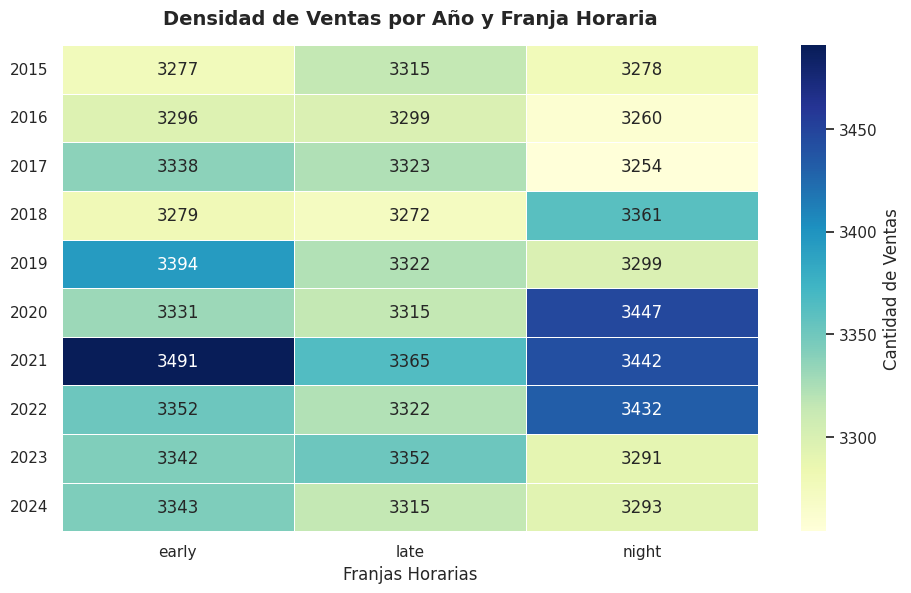

In [46]:
actividad_por_franjas = actividad_por_franjas[["early", "late", "night"]] #Seaborn respeta el orden de las columnas del dataframe. Asi que ordenamos las franjas.

# tamaño del gráfico
plt.figure(figsize=(10, 6))

# Dibujamos el Heatmap
sns.heatmap(
    data=actividad_por_franjas,
    annot=True,           # muestra los números dentro de cada celda
    fmt="d",              # Formato de número entero (d = integer)
    cmap="YlGnBu",        # Paleta secuencial
    linewidths=0.5,       # añadir línea de separación entre celdas
    cbar_kws={'label': 'Cantidad de Ventas'} # Etiqueta para la barra de color
)

# 3. Título y etiquetas
plt.title('Densidad de Ventas por Año y Franja Horaria', fontsize=14, pad=15, fontweight='bold')
plt.ylabel('', fontsize=12) # dejamos el titulo vacio, añadir "años" es redondante
plt.xlabel('Franjas Horarias', fontsize=12)
plt.yticks(rotation=0) # gira las etiquetas del eje Y (0 = horizontal)
plt.show()


» Interpreta què implica per al negoci.

• 2015 - 2019: Las ventas eran estables y moderadas en todas las franjas.

• 2020 - 2022: Explotaron las compras por la noche

• 2023 - 2024: La noche cayó drásticamente y el volumen se trasladó a la mañana (franja líder actual con unas 3343 ventas anuales).

• Franja Más Débil: La tarde se mantiene como el horario más plano manteniéndose siempre en un rango medio-bajo (entre las 3272 y 3365 ventas).



# Nivell 2 – Anàlisi relacional i patrons avançats

# Exercici 1: Anàlisi de productes i captació d'usuaris

Els productes que generen més ingressos també impulsen el creixement del negoci mitjançant la captació de nous usuaris, o bé el negoci depèn principalment d'usuaris recurrents comprant els mateixos productes?

> 1. Combina les taules necessàries.

Usaremos df2 que ya combina transactions con productos.

> 2. Defineix un criteri de nou usuari si la transacció analitzada és la primera cronològicament que realitza al sistema es_nou_usuari = True / False.

Pandas marca con True los registros duplicados y deja la primera fila como False porque "aún no está duplicada". Queremos justo lo contrario, asi que usaremos el símbolo de la virgulilla que invierte los valores.

De esta manera, la primera fila pasa a ser True y todas las siguientes compras del mismo usuario se convierten en False.

In [47]:
# Primero ordenamos el dataframe cronologicamente
df_ordenado = df2.sort_values(by="timestamp")

# evaluamos los duplicados en la columna user_id, marcamos como True el primer registro
df_ordenado["es_nou_usuari"] = ~df_ordenado.duplicated(subset=["user_id"], keep="first")

# comprobamos con un user_id al azar
test = df_ordenado[df_ordenado["user_id"] == 2313]
test[["user_id", "timestamp", "es_nou_usuari"]]

,user_id,timestamp,es_nou_usuari
187664,2313,2015-03-05 09:59:07,True
25817,2313,2015-04-18 18:29:21,False
25818,2313,2015-04-18 18:29:21,False
249106,2313,2015-09-04 15:31:36,False
124028,2313,2016-01-22 21:06:53,False
124027,2313,2016-01-22 21:06:53,False
250846,2313,2016-06-16 00:30:22,False
160113,2313,2016-09-06 10:46:29,False
160110,2313,2016-09-06 10:46:29,False
160111,2313,2016-09-06 10:46:29,False



> 3. Agrega la informació per producte i calcula les mètriques següents:


*   Ingressos totals.
*   Variabilitat dels ingressos
*   Nombre de nous usuaris.
*   Percentatge de nous usuaris sobre el total de compradors del producte.

In [48]:
# Agrupamos por id del producto y su nombre y calculamos las 3 primeras métricas
metricas = df_ordenado.groupby(['id', 'product_name']).agg(
    ingresos_totales=('amount', 'sum'),             # Calculamos los ingresos
    variabilidad_ingresos=('amount', 'std'),        # Calculamos la desviación estándar
    nuevos_usuarios=('es_nou_usuari', 'sum'),   # Cuenta los True
    total_compradores=('user_id', 'nunique')     # Cuenta usuarios únicos que compraron el producto
).reset_index()

# Calculamos el porcentaje de nuevos usuarios
metricas['porcentaje_nuevos_usuarios'] = metricas['nuevos_usuarios'] / metricas['total_compradores'] * 100


> 4. Creació d'una tipologia analítica de productes a partir de les mètriques calculades, per exemple:

*   Captador: alta captació de nous usuaris.
*   Recurrent: ingressos elevats però baixa captació.
*   Emergent: baixa facturació però bona captació.
*   Estancat: baixos ingressos i baixa captació.

In [49]:
# Calculamos las medianas de referencia
mediana_ingresos = metricas["ingresos_totales"].median()
mediana_captacion = metricas['porcentaje_nuevos_usuarios'].median()

# Creamos una función que crea una columna nueva por tipología
def asignar_tipologia(row):
    # evaluamos los valores de las filas segun las medianas
    alto_ingreso = row["ingresos_totales"] >= mediana_ingresos
    alta_captacion = row["porcentaje_nuevos_usuarios"] >= mediana_captacion

    if alto_ingreso and alta_captacion:
        return "Captador"
    elif alto_ingreso and not alta_captacion:
        return "Recurrent"
    elif not alto_ingreso and alta_captacion:
        return "Emergent"
    else:
        return "Estancat"

metricas["tipologia"] = metricas.apply(asignar_tipologia, axis=1)

> 5. Construeix una visualització que permeti analitzar la relació entre les dimensions principals. Per exemple, un scatter plot amb:

*   Eix X → ingressos totals per producte.
*   Eix Y → nombre de nous usuaris.
*   Mida del punt → variabilitat dels ingressos.
*   Color del punt → tipologia analítica del producte.

Usaremos px.scatter, de la librería Plotly Express que se utiliza para crear gráficos de dispersión con cuatro dimensiones a la vez.

In [50]:
# Creamos un gráfico Scatter Plot
fig = px.scatter(
    metricas,
    x='ingresos_totales',
    y='nuevos_usuarios',
    size='variabilidad_ingresos',
    color='tipologia', #personalizamos que la variable tipologia se coloree
    hover_name='product_name',  # muestra el nombre del producto como titulo del Tooltip
    title='Ingresos vs. Captación de Nuevos Usuarios',
    labels={
        'ingresos_totales': 'Ingresos Totales (€)', # renombramos las etiquetas del Tooltip
        'nuevos_usuarios': 'Número de Nuevos Usuarios',
        'tipologia': 'Tipología de Producto',
        'variabilidad_ingresos': 'Variabilidad de Ingresos'
    },
    color_discrete_map={         # asignamos un color a las tipologias de prodcuto
        'Captador': '#2ecc71',   # Verde
        'Recurrent': '#3498db',  # Azul
        'Emergent': '#f1c40f',   # Amarillo
        'Estancat': '#e74c3c'    # Rojo
    }
)
fig.show()




> No es tracta només de mostrar gràfics, sinó d'interpretar què implica per al negoci no captar nous usuaris.



**Productos Recurrentes** (Muchos ingresos, baja captación)

Son productos comprados por clientes fidelizados. El riesgo está en que si estos clientes actuales cambian de hábitos, o se van a la competencia, nadie más comprará esos productos.

**Productos Estancados** (Pocos ingresos, baja captación)

Son productos en declive o nichos muy cerrados que no generan volumen ni atraen.


En ambos casos, deberemos decidir si se reinventa el producto o si lo retiramos del mercado.

# Exercici 2: Anàlisi geogràfica company–usuari i oportunitats d'expansió

El negoci està basat en mercats locals (mateix país usuari–companyia) o hi ha una oportunitat real d'expansió internacional obrint més companyies en certs països?

> 1. Combina les taules necessàries.


In [51]:
usuarios = leer_fichero('/content/drive/MyDrive/Colab Notebooks/usuarios.csv', sep=';',encoding='latin1')
usuarios.head()

,id,country,city,signup_date,user_segment,income_band,continent
0,1,United States,New York,23/04/2014,young_professional,high,US\r
1,10,United States,San Jose,19/10/2013,premium,high,US\r
2,100,United States,San Jose,20/04/2015,frequent_shopper,very_high,US\r
3,1000,Germany,Stuttgart,28/10/2015,occasional,low,UE\r
4,1001,Germany,Cologne,22/05/2014,premium,very_high,UE\r


In [52]:
usuarios['continent'] = usuarios['continent'].str.rstrip('\r')
usuarios.head()

,id,country,city,signup_date,user_segment,income_band,continent
0,1,United States,New York,23/04/2014,young_professional,high,US
1,10,United States,San Jose,19/10/2013,premium,high,US
2,100,United States,San Jose,20/04/2015,frequent_shopper,very_high,US
3,1000,Germany,Stuttgart,28/10/2015,occasional,low,UE
4,1001,Germany,Cologne,22/05/2014,premium,very_high,UE


In [53]:
# el Dataframe tx_co (merge de transactions y companies) tiene muchas columnas que no nos interesan ahora, guardamos las que nos convienen.
df3 = tx_co[['id','amount', 'product_ids','lat','longitude','shipping_amount','is_international', 'distance_km', 'company_id', 'company_name', 'country', 'user_id']]
df3.head()

,id,amount,product_ids,lat,longitude,shipping_amount,is_international,distance_km,company_id,company_name,country,user_id
0,CDDA7E40-544D-47BB-A4ED-671DD8A950D9,176.45,"75, 73, 98",59.620510,16.559977,0.00,0,129.25,b-2466,Amet Lorem LLP,Spain,2313
1,09456357-8E9B-475A-8257-87A023699964,206.65,3,45.764588,4.843057,4.99,0,0.57,b-2342,Fringilla Porttitor Incorporated,Sweden,554
2,C47C7C84-C174-4973-A76B-825A9DB5582A,548.77,"92, 85, 36, 23",39.224213,-0.288066,0.00,1,1498.24,b-2250,Amet Nulla Donec Corporation,Italy,3834
3,2FB526AA-3844-4DDF-AC09-2EBCC255EE76,411.55,"5, 27",39.475985,-0.376419,0.00,0,0.68,b-2610,Egestas Nunc Sed Limited,Italy,1972
4,0D877407-B85E-40D2-9229-6BD6F2B8DF0A,410.65,"38, 32, 82, 62",51.436570,5.478526,0.00,0,78.46,b-2454,Justo Eu Arcu Ltd,Italy,3097


In [54]:
# Combinamos df3 con usuarios
df_full = pd.merge(
    df3,
    usuarios,
    left_on=['user_id'],
    right_on=['id'],
    how='left',
    suffixes=('_tx', '_user')
)
display(df_full.head())

,id_tx,amount,product_ids,lat,longitude,shipping_amount,is_international,distance_km,company_id,company_name,country_tx,user_id,id_user,country_user,city,signup_date,user_segment,income_band,continent
0,CDDA7E40-544D-47BB-A4ED-671DD8A950D9,176.45,"75, 73, 98",59.620510,16.559977,0.00,0,129.25,b-2466,Amet Lorem LLP,Spain,2313,2313,Sweden,Västerås,20/11/2013,established,medium,UE
1,09456357-8E9B-475A-8257-87A023699964,206.65,3,45.764588,4.843057,4.99,0,0.57,b-2342,Fringilla Porttitor Incorporated,Sweden,554,554,France,Lyon,12/06/2014,frequent_shopper,medium,UE
2,C47C7C84-C174-4973-A76B-825A9DB5582A,548.77,"92, 85, 36, 23",39.224213,-0.288066,0.00,1,1498.24,b-2250,Amet Nulla Donec Corporation,Italy,3834,3834,Netherlands,The Hague,06/12/2013,frequent_shopper,medium,UE
3,2FB526AA-3844-4DDF-AC09-2EBCC255EE76,411.55,"5, 27",39.475985,-0.376419,0.00,0,0.68,b-2610,Egestas Nunc Sed Limited,Italy,1972,1972,Spain,Valencia,09/04/2014,frequent_shopper,low,UE
4,0D877407-B85E-40D2-9229-6BD6F2B8DF0A,410.65,"38, 32, 82, 62",51.436570,5.478526,0.00,0,78.46,b-2454,Justo Eu Arcu Ltd,Italy,3097,3097,Netherlands,Eindhoven,28/11/2014,occasional,medium,UE



> 2. Crea una variable clau d'anàlisi: compra_local = True/False.



In [55]:
#Se crea una columna compra_local que indica True si el país de la compañía es el mismo que el país del usuario.
df_full['compra_local'] = df_full['country_tx'] == df_full['country_user']
df_full.head()

,id_tx,amount,product_ids,lat,longitude,shipping_amount,is_international,distance_km,company_id,company_name,country_tx,user_id,id_user,country_user,city,signup_date,user_segment,income_band,continent,compra_local
0,CDDA7E40-544D-47BB-A4ED-671DD8A950D9,176.45,"75, 73, 98",59.620510,16.559977,0.00,0,129.25,b-2466,Amet Lorem LLP,Spain,2313,2313,Sweden,Västerås,20/11/2013,established,medium,UE,False
1,09456357-8E9B-475A-8257-87A023699964,206.65,3,45.764588,4.843057,4.99,0,0.57,b-2342,Fringilla Porttitor Incorporated,Sweden,554,554,France,Lyon,12/06/2014,frequent_shopper,medium,UE,False
2,C47C7C84-C174-4973-A76B-825A9DB5582A,548.77,"92, 85, 36, 23",39.224213,-0.288066,0.00,1,1498.24,b-2250,Amet Nulla Donec Corporation,Italy,3834,3834,Netherlands,The Hague,06/12/2013,frequent_shopper,medium,UE,False
3,2FB526AA-3844-4DDF-AC09-2EBCC255EE76,411.55,"5, 27",39.475985,-0.376419,0.00,0,0.68,b-2610,Egestas Nunc Sed Limited,Italy,1972,1972,Spain,Valencia,09/04/2014,frequent_shopper,low,UE,False
4,0D877407-B85E-40D2-9229-6BD6F2B8DF0A,410.65,"38, 32, 82, 62",51.436570,5.478526,0.00,0,78.46,b-2454,Justo Eu Arcu Ltd,Italy,3097,3097,Netherlands,Eindhoven,28/11/2014,occasional,medium,UE,False




> 3. Analitza el comportament global:

*   Percentatge de transaccions locals vs internacionals.
*   Percentatge de facturació local vs internacional.



In [56]:
# calculamos la proporcion de filas que tienen True o False en la columna compra_local
porcentaje_transacciones_locales = round((df_full['compra_local'] == True).mean() * 100, 2)
porcentaje_transacciones_intl = round((df_full['compra_local'] == False).mean() * 100, 2)

In [57]:
# calculamos la facturacion local, internacional y total y sacamos los porcentajes
facturacion_local = df_full[df_full["compra_local"] == True]['amount'].sum()
facturacion_intl = df_full[df_full["compra_local"] == False]['amount'].sum()

facturacion_total = df_full['amount'].sum()

porcentaje_facturacion_local = round((facturacion_local / facturacion_total) * 100, 2)
porcentaje_facturacion_intl = round((facturacion_intl / facturacion_total) * 100, 2)



> 4. Anàlisi per país de l'usuari, per cada país d'usuari:

*   % de compres a companyies del mateix país.
*   % de compres a companyies estrangeres.
*   Import total comprat.



In [58]:
# # usar mean en una columna booleana nos da directamente la proporcion
compras_locales = df_full.groupby('country_user').agg({'compra_local': 'mean','amount': 'sum'})

# calculamos la proporción internacional (1 - proporcion_local)
compras_locales['compra_intl'] = 1 - compras_locales['compra_local']

# transformamos a porcentaje
compras_locales['compra_local'] = round(compras_locales['compra_local'] * 100, 2)
compras_locales['compra_intl'] = round(compras_locales['compra_intl'] * 100, 2)

compras_locales = compras_locales.reset_index()
compras_locales


,country_user,compra_local,amount,compra_intl
0,Canada,9.71,2688940.83,90.29
1,France,6.28,2488997.24,93.72
2,Germany,16.94,2573251.67,83.06
3,Italy,17.10,2603565.73,82.90
4,Netherlands,19.32,2675165.65,80.68
5,Poland,0.00,2512973.74,100.00
6,Portugal,0.00,2638023.31,100.00
7,Spain,1.74,2693566.24,98.26
8,Sweden,21.30,2490810.72,78.70
9,United Kingdom,17.29,2838889.37,82.71




> 5. Anàlisi per país de companyia, per cada país de companyia calcula quina part de la seva facturació ve de:

*   Usuaris locals.
*   Usuaris estrangers.


In [59]:
# usamos el codigo anterior, cambiando el pais del usuario por el pais de la compañia
usuarios_locales = df_full.groupby('country_tx').agg({'compra_local': 'mean','amount': 'sum'})

# calculamos la proporción internacional (1 - proporcion_local)
usuarios_locales['compra_intl'] = 1 - usuarios_locales['compra_local']

# transformamos a porcentaje
usuarios_locales['compra_local'] = round(usuarios_locales['compra_local'] * 100, 2)
usuarios_locales['compra_intl'] = round(usuarios_locales['compra_intl'] * 100, 2)

usuarios_locales = usuarios_locales.reset_index()
usuarios_locales

,country_tx,compra_local,amount,compra_intl
0,Australia,0.00,699013.06,100.00
1,Belgium,0.00,952208.75,100.00
2,Canada,46.04,558568.76,53.96
3,China,0.00,239034.47,100.00
4,France,11.36,1416084.26,88.64
5,Germany,11.12,4020364.07,88.88
6,Ireland,0.00,715220.46,100.00
7,Italy,10.72,4087557.38,89.28
8,Netherlands,11.50,4506571.38,88.50
9,New Zealand,0.00,705159.09,100.00




> 6. Escull una visualització que expliqui clarament el fenomen.



In [60]:
# usamos choropleth que está adaptado para un analisis geografico (identificar oportunidades de expansión por país)
fig = px.choropleth(
    compras_locales,
    locations='country_user',
    locationmode='country names',
    color='compra_intl',
    hover_name='country_user', # muestra el nombre del pais como titulo del Tooltip
    hover_data={               # datos que aparecen en el Tooltip
        'country_user': False,
        'amount': ':,.0f',
        'compra_local': ':.2f',
        'compra_intl': ':.2f'
    },
    labels={                  # renombramos las etiquetas del Tooltip
        'amount': 'Volumen (€)',
        'compra_local': '% Local',
        'compra_intl': '% Internacional'
    },

    color_continuous_scale='Reds',
    range_color=(78, 100) # ajustamos el degradado a la escala de los valores ('compra_intl' min = 78.7 y max = 100)
)

fig.update_layout(
    width=1200,
    height=700
)

fig.show()



> 7. Interpretació estratègica:

*   En quins països valdria la pena obrir més companyies locals?
*   Hi ha països amb demanda però poca oferta local?
*   El negoci depèn massa de companyies d'un sol país?
*   Obrir companyies locals reduiria fricció o milloraria conversió?



Las transacciones internacionales dominan en todos los países analizados. Países como Portugal (100%), Polonia (100%), España (98,26%) y Francia (93,72%) presentan una fuerte dependencia de proveedores extranjeros. Dado que además concentran volúmenes de compra superiores a 2,4 millones, podrían representar oportunidades potenciales para incrementar la presencia de compañías locales.

Aunque un porcentaje de compras internacionales elevado es comun a todos los países, la estrategia de expansión debería priorizar mercados como España, Portugal, Canadá y Estados Unidos, ya que combinan una elevada dependencia internacional con los mayores volúmenes de facturación.

Con los datos disponibles no es posible determinar si abrir compañías locales reduciría la fricción o mejoraría la conversión. El análisis únicamente muestra que una gran parte de las compras se realizan a compañías extranjeras, pero no proporciona información sobre experiencia de usuarios, tiempos de compra, costes adicionales o tasas de conversión que permitan evaluar dicho impacto.

# Nivell 3 - Visualització executiva i storytelling

# Exercici 1: Mini-dashboard departamental